# NYC Taxi — Öğrenci 5 ders gösterimi: pandas mı Spark mı?

**Soru:** Veri büyüdükçe klasik yaklaşım (pandas + CSV) **işleme** hızında ne zaman Spark'ın gerisine düşüyor? Dosya formatı bu cevabı değiştiriyor mu?

**Ne yaptım?**
1. Üç ileri analitik işlemi (**groupby, join, window**) hem pandas hem PySpark ile yazdım.
2. Bu işlemleri Öğrenci 1'in 5 boyut setinde (100K → 19M kayıt), **CSV ve Parquet** üzerinde çalıştırdım. Toplam 20 kombinasyon, her ölçüm 1 ısınma + 3 tekrar.
3. Süreyi, tepe belleği ve throughput'u ölçtüm. Her kombinasyonda iki motorun **aynı sonucu** verdiğini checksum ile doğruladım.
4. Ek deneyler: Spark'ı **önbellekle** (cache) çalıştırdım, veriyi **sentetik olarak 3 katına (57M)** çıkardım ve **dosya düzeninin** (Parquet row group sayısı) Spark'a etkisini ölçtüm.
5. Beş öğrencinin sonuçlarını tek sayfalık bir **dashboard**'da topladım.

**Kapsam:** Okuma ve depolama performansını Öğrenci 1 ölçtü. Burada işleme ölçüldü.

**İçerik** · [1. İşlemler](#1.-Üç-işlem,-iki-motor) · [2. Deney düzeni](#2.-Deney-düzeni) · [3. Uçtan uca](#3.-Bulgu-1-—-Uçtan-uca-süre) · [4. Format](#4.-Bulgu-2-—-Format,-motordan-daha-belirleyici) · [5. İşlem türü](#5.-Bulgu-3-—-Cevap-işleme-göre-değişiyor) · [6. Bellek](#6.-Bellek) · [7. Doğrulama](#7.-İki-motor-aynı-sonucu-verdi-mi?) · [8. Ek deneyler](#8.-Ek-deneyler:-önbellek,-57M,-dosya-düzeni) · [9. Dashboard](#9.-Dashboard) · [10. Sonuç](#10.-Sonuç)

> Bu notebook yalnızca `reports/results/` altındaki kayıtlı ölçümleri okur. Veri veya Spark kurulumu gerekmez. Ölçümleri yeniden üretmek için: `python -m src.benchmark_processing`.

In [1]:
import inspect
import io
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import IFrame, Image, Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
INK = "#52514e"


def tr_dec(x, n=2):
    return f"{x:,.{n}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def tr_int(x):
    return f"{int(round(x)):,}".replace(",", ".")


def md(text):
    display(Markdown(text))


def show(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    display(Image(buffer.getvalue()))


def show_code(*functions):
    for fn in functions:
        md(f"`{fn.__module__}.{fn.__name__}`\n```python\n{inspect.getsource(fn).rstrip()}\n```")

from src import benchmark_processing as bp
from src.config import RESULTS_DIR
from src.plots_processing import (ENGINE_COLOR, ENGINE_LABEL, FORMAT_LABEL, FORMAT_STYLE,
                                  OP_TITLE, crossover_rows, memory_per_row_kb)

SIZE_LABEL = {"100k": "100K", "1m": "1M", "5m": "5M", "10m": "10M", "full": "19M"}
SIZES = list(SIZE_LABEL.values())
COMBOS = [("pandas", "csv"), ("pandas", "parquet_snappy"), ("spark", "csv"), ("spark", "parquet_snappy")]


def combo_name(engine, fmt):
    return f"{ENGINE_LABEL[engine]} + {FORMAT_LABEL[fmt]}"


def log_axes(ax, ylabel):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Kayıt sayısı (log)", color=INK)
    ax.set_ylabel(ylabel, color=INK)
    ax.set_xticks([1e5, 1e6, 1e7], ["100K", "1M", "10M"])
    ax.minorticks_off()


def plot_lines(ax, frame, ycol):
    for engine, fmt in COMBOS:
        grp = frame[(frame["engine"] == engine) & (frame["format"] == fmt)].sort_values("rows")
        ls, marker = FORMAT_STYLE[fmt]
        ax.plot(grp["rows"], grp[ycol], color=ENGINE_COLOR[engine], linestyle=ls, marker=marker,
                linewidth=2, markersize=6, label=combo_name(engine, fmt))


summary_all = pd.read_csv(RESULTS_DIR / bp.SUMMARY_FILE)
# Ana karşılaştırma: pandas vs dosyadan okuyan Spark, 5 gerçek boyut. Ek deneyler (önbellek,
# sentetik 57M, dosya düzeni) §8'de summary_all'dan okunur.
summary = summary_all[summary_all["engine"].isin(["pandas", "spark"])
                      & summary_all["size"].isin(SIZE_LABEL)].copy()
summary["size_label"] = summary["size"].map(SIZE_LABEL)
e2e = bp.end_to_end(summary)
e2e["size_label"] = e2e["size"].map(SIZE_LABEL)
FULL = int(e2e.loc[e2e["size"] == "full", "rows"].iloc[0])

assert len(e2e) == 20 and summary["n_failed"].sum() == 0 and summary.loc[summary["op"] != "startup", "n_ok"].min() == 3
md(f"**20 kombinasyon** yüklendi: 2 motor × 2 format × 5 boyut (100K … {tr_int(FULL)} kayıt). "
   "Başarısız ölçüm yok. Her işlem 3 tekrarlı, Spark oturum açılışı süreç başına bir kez ölçüldü.")

**20 kombinasyon** yüklendi: 2 motor × 2 format × 5 boyut (100K … 18.999.282 kayıt). Başarısız ölçüm yok. Her işlem 3 tekrarlı, Spark oturum açılışı süreç başına bir kez ölçüldü.

## 1. Üç işlem, iki motor

| İşlem | Ne hesaplıyor? | Neden seçildi? |
|---|---|---|
| **groupby** | Biniş saatine göre yolculuk sayısı, ortalama mesafe, ortalama ücret, toplam gelir (24 satır) | En yaygın toplama işlemi |
| **join** | Yolculuklar ⋈ 265 satırlık bölge tablosu, ilçeye göre sayım ve ortalama tutar | Büyük tablo ile küçük tablonun birleştirilmesi |
| **window** | Her biniş bölgesinde en yüksek tutarlı 3 yolculuk: `row_number() over (partition by PULocationID ...)` | Verinin bölümlere ayrılıp sıralanması |

Aşağıdaki kodlar ölçümde çalışan gerçek fonksiyonlar (`src/benchmark_processing.py`):

In [2]:
md("### groupby")
show_code(bp.pandas_groupby_hour, bp.spark_groupby_hour)

### groupby

`src.benchmark_processing.pandas_groupby_hour`
```python
def pandas_groupby_hour(df: pd.DataFrame) -> pd.DataFrame:
    return (
        df.groupby(df["tpep_pickup_datetime"].dt.hour.rename("hour"))
        .agg(trips=("PULocationID", "size"), avg_distance=("trip_distance", "mean"),
             avg_fare=("fare_amount", "mean"), revenue=("total_amount", "sum"))
        .reset_index()
    )
```

`src.benchmark_processing.spark_groupby_hour`
```python
def spark_groupby_hour(df):
    from pyspark.sql import functions as F

    return df.groupBy(F.hour("tpep_pickup_datetime").alias("hour")).agg(
        F.count(F.lit(1)).alias("trips"), F.avg("trip_distance").alias("avg_distance"),
        F.avg("fare_amount").alias("avg_fare"), F.sum("total_amount").alias("revenue"),
    )
```

In [3]:
md("### join")
show_code(bp.pandas_join_borough, bp.spark_join_borough)
md("### window")
show_code(bp.pandas_window_top3, bp.spark_window_top3)

### join

`src.benchmark_processing.pandas_join_borough`
```python
def pandas_join_borough(df: pd.DataFrame, zones: pd.DataFrame) -> pd.DataFrame:
    joined = df[["PULocationID", "total_amount"]].merge(
        zones[["LocationID", "Borough"]], left_on="PULocationID", right_on="LocationID", how="inner"
    )
    return (
        joined.groupby("Borough", dropna=False)
        .agg(trips=("total_amount", "size"), avg_total=("total_amount", "mean"))
        .reset_index()
    )
```

`src.benchmark_processing.spark_join_borough`
```python
def spark_join_borough(df, zones):
    from pyspark.sql import functions as F

    joined = df.select("PULocationID", "total_amount").join(
        zones.select("LocationID", "Borough"), df["PULocationID"] == zones["LocationID"], "inner"
    )
    return joined.groupBy("Borough").agg(
        F.count(F.lit(1)).alias("trips"), F.avg("total_amount").alias("avg_total")
    )
```

### window

`src.benchmark_processing.pandas_window_top3`
```python
def pandas_window_top3(df: pd.DataFrame) -> pd.DataFrame:
    ranked = df[["PULocationID", "total_amount"]].sort_values(
        ["PULocationID", "total_amount"], ascending=[True, False], kind="stable"
    )
    return ranked.groupby("PULocationID", sort=False).head(TOP_N)
```

`src.benchmark_processing.spark_window_top3`
```python
def spark_window_top3(df):
    from pyspark.sql import Window
    from pyspark.sql import functions as F

    w = Window.partitionBy("PULocationID").orderBy(F.desc("total_amount"))
    return (df.select("PULocationID", "total_amount")
            .withColumn("rn", F.row_number().over(w))
            .filter(F.col("rn") <= TOP_N))
```

## 2. Deney düzeni

| Bileşen | Seçim |
|---|---|
| **Boyutlar** | 100K, 1M, 5M, 10M, 19M (Öğrenci 1'in iç içe boyut setleri) |
| **Formatlar** | CSV ve Parquet (snappy). İki motor da aynı 6 kolonu okur. |
| **Çalışma modeli** | Her motor kendi doğal yoluyla çalışır. **pandas** veriyi bir kez belleğe yükler, işlemler bellekte çalışır. **Spark** tembeldir, her işlem dosyadan okuyarak çalışır. |
| **Uçtan uca süre** | pandas = yükleme + 3 işlem. Spark = oturum açılışı + 3 işlem. |
| **Tekrar** | Her işlem 1 ısınma + 3 tekrar (ortalama ± std) |
| **İzolasyon** | Her motor × boyut × format ayrı bir alt süreçte çalışır. pandas ve Spark aynı anda çalışmaz. |
| **Bellek** | Süreç ağacının (Python + JVM) tepe RSS'i, 50 ms'de bir örneklenir |
| **Makine** | i7-13700H (20 iş parçacığı), 32 GB RAM, NVMe SSD. Spark `local[*]` modunda. |

## 3. Bulgu 1 — Uçtan uca süre

**CSV'de Spark, pandas'ı ~16,1M kayıtta geçiyor. Parquet'te ise 18.999.282 kayda kadar hiç geçemiyor: 19M'de pandas + Parquet 5,3 sn, Spark + Parquet 13,5 sn.**

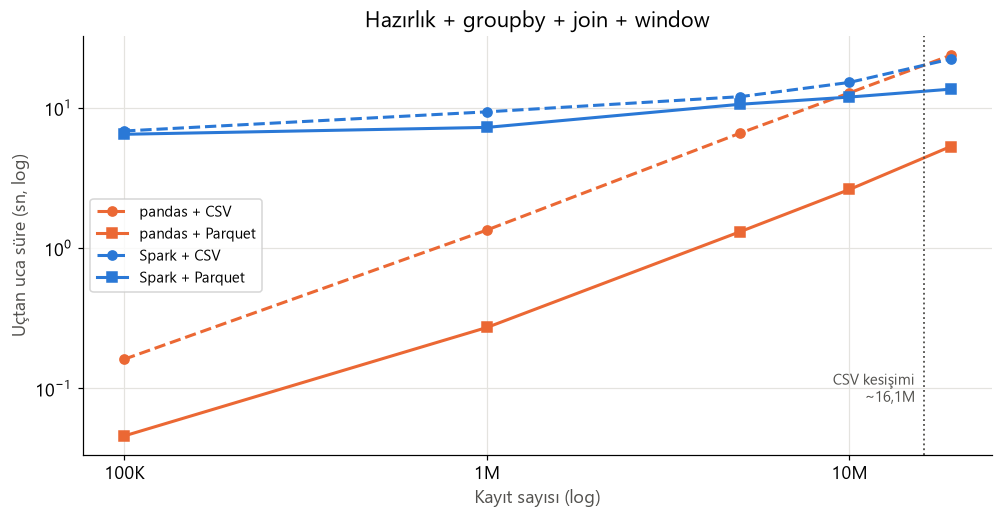

,100K,1M,5M,10M,19M
Uçtan uca (sn),,,,,
pandas + CSV,"0,16","1,34","6,58","12,73","23,56"
pandas + Parquet,"0,05","0,27","1,31","2,61","5,28"
Spark + CSV,"6,81","9,33","11,96","15,11","22,17"
Spark + Parquet,"6,45","7,23","10,56","11,89","13,53"


In [4]:
cross_csv = crossover_rows(e2e, "csv")
cross_parquet = crossover_rows(e2e, "parquet_snappy")
full = e2e[e2e["size"] == "full"].set_index(["engine", "format"])["total_s"]
csv_text = f"~{tr_dec(cross_csv / 1e6, 1)}M kayıtta" if cross_csv else "hiçbir boyutta"
parquet_text = (f"~{tr_dec(cross_parquet / 1e6, 1)}M kayıtta geçiyor" if cross_parquet
                else f"{tr_int(FULL)} kayda kadar hiç geçemiyor")
md(f"**CSV'de Spark, pandas'ı {csv_text} geçiyor. Parquet'te ise {parquet_text}: "
   f"19M'de pandas + Parquet {tr_dec(full[('pandas', 'parquet_snappy')], 1)} sn, "
   f"Spark + Parquet {tr_dec(full[('spark', 'parquet_snappy')], 1)} sn.**")

fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
plot_lines(ax, e2e, "total_s")
log_axes(ax, "Uçtan uca süre (sn, log)")
if cross_csv:
    ax.axvline(cross_csv, color=INK, linestyle=":", linewidth=1.2)
    ax.annotate(f"CSV kesişimi\n~{tr_dec(cross_csv / 1e6, 1)}M", (cross_csv, 0.08), ha="right",
                xytext=(-6, 0), textcoords="offset points", fontsize=10, color=INK)
ax.set_title("Hazırlık + groupby + join + window")
ax.legend(fontsize=10)
show(fig)

table = e2e.pivot(index=["engine", "format"], columns="size_label", values="total_s")[SIZES]
table.index = [combo_name(*i) for i in table.index]
display(table.rename_axis("Uçtan uca (sn)").rename_axis(None, axis=1).map(lambda v: tr_dec(v, 2)))

In [5]:
startup = summary[summary["op"] == "startup"]["seconds_mean"]
spark_small = summary[(summary["engine"] == "spark") & (summary["size"] == "100k")
                      & (summary["format"] == "parquet_snappy") & summary["op"].isin(bp.OPERATIONS)]
md(f"**Spark'ın sabit maliyetleri:** oturum açılışı {tr_dec(startup.min(), 1)}–{tr_dec(startup.max(), 1)} sn. "
   f"100K Parquet'te üç işlemin her biri {tr_dec(spark_small['seconds_mean'].min(), 2)}–{tr_dec(spark_small['seconds_mean'].max(), 2)} sn sürüyor; "
   "bu sürenin çoğu planlama, görev başlatma ve sonucu sürücüye toplama. "
   "pandas'ta bu sabit maliyetler yok. Spark'ın bu maliyetleri amorti etmesi için çok veri gerekiyor.")

**Spark'ın sabit maliyetleri:** oturum açılışı 5,5–5,8 sn. 100K Parquet'te üç işlemin her biri 0,24–0,48 sn sürüyor; bu sürenin çoğu planlama, görev başlatma ve sonucu sürücüye toplama. pandas'ta bu sabit maliyetler yok. Spark'ın bu maliyetleri amorti etmesi için çok veri gerekiyor.

## 4. Bulgu 2 — Format, motordan daha belirleyici

In [6]:
f19 = summary[summary["size"] == "full"].copy()
f19["combo"] = [combo_name(e, f) for e, f in zip(f19["engine"], f19["format"])]
step = f19.pivot(index="op", columns="combo", values="seconds_mean")
step = step.rename(index={"load": "Hazırlık: pandas yükleme", "startup": "Hazırlık: Spark açılışı"})
step = step.loc[["Hazırlık: pandas yükleme", "Hazırlık: Spark açılışı", *bp.OPERATIONS],
                [combo_name(*c) for c in COMBOS]]
step.index = [OP_TITLE.get(i, i) for i in step.index]

spark_gb = step.loc[OP_TITLE["groupby_hour"], ["Spark + CSV", "Spark + Parquet"]]
pandas_load = step.loc["Hazırlık: pandas yükleme", ["pandas + CSV", "pandas + Parquet"]]
md(f"**19M'de Spark groupby CSV'den {tr_dec(spark_gb.iloc[0], 1)} sn, Parquet'ten {tr_dec(spark_gb.iloc[1], 1)} sn sürüyor "
   f"({tr_dec(spark_gb.iloc[0] / spark_gb.iloc[1], 1)}×). pandas'ta CSV cezası yüklemede ödeniyor: "
   f"{tr_dec(pandas_load.iloc[0], 1)} sn ve {tr_dec(pandas_load.iloc[1], 2)} sn ({tr_dec(pandas_load.iloc[0] / pandas_load.iloc[1], 0)}×).**")
display(step.rename_axis(f"{tr_int(FULL)} kayıt, sn").map(lambda v: "—" if pd.isna(v) else tr_dec(v, 2)))

**19M'de Spark groupby CSV'den 5,9 sn, Parquet'ten 0,9 sn sürüyor (6,4×). pandas'ta CSV cezası yüklemede ödeniyor: 18,8 sn ve 0,37 sn (51×).**

combo,pandas + CSV,pandas + Parquet,Spark + CSV,Spark + Parquet
"18.999.282 kayıt, sn",,,,
Hazırlık: pandas yükleme,"18,82","0,37",—,—
Hazırlık: Spark açılışı,—,—,"5,48","5,81"
groupby: saate göre özet,"0,70","0,70","5,86","0,91"
join: bölge tablosu → ilçe,"1,97","2,12","4,20","0,71"
window: bölge başına ilk 3,"2,07","2,09","6,62","6,09"


**Neden?**
- **CSV metindir.** Her satırdaki her alan okunup sayıya ve tarihe çevrilir (parse). Hangi kolon gerekirse gereksin bütün satır okunur.
- **Parquet sütunludur.** İkili, sıkıştırılmış ve tiplidir. Yalnızca gereken kolonlar okunur, metin parse edilmez.
- **Spark tembeldir.** Önbellek (`cache`) kullanılmadığı için CSV'yi her işlemde yeniden parse eder. pandas bu maliyeti yalnızca bir kez, yüklemede öder. Ama 19M'de bu bir kerelik maliyet bile toplam sürenin büyük kısmı.

Sonuç: **pandas + CSV'den pandas + Parquet'e geçmek, Spark'a geçmekten daha büyük kazanç sağlıyor.** Bu bulgu Öğrenci 1'in okuma ölçümleriyle tutarlı.

## 5. Bulgu 3 — Cevap işleme göre değişiyor

**Parquet'te join'de Spark ~4,5M kayıttan itibaren önde, 19M'de 3,0× hızlı. window'da ise 19M'de hâlâ 2,9× geride.**

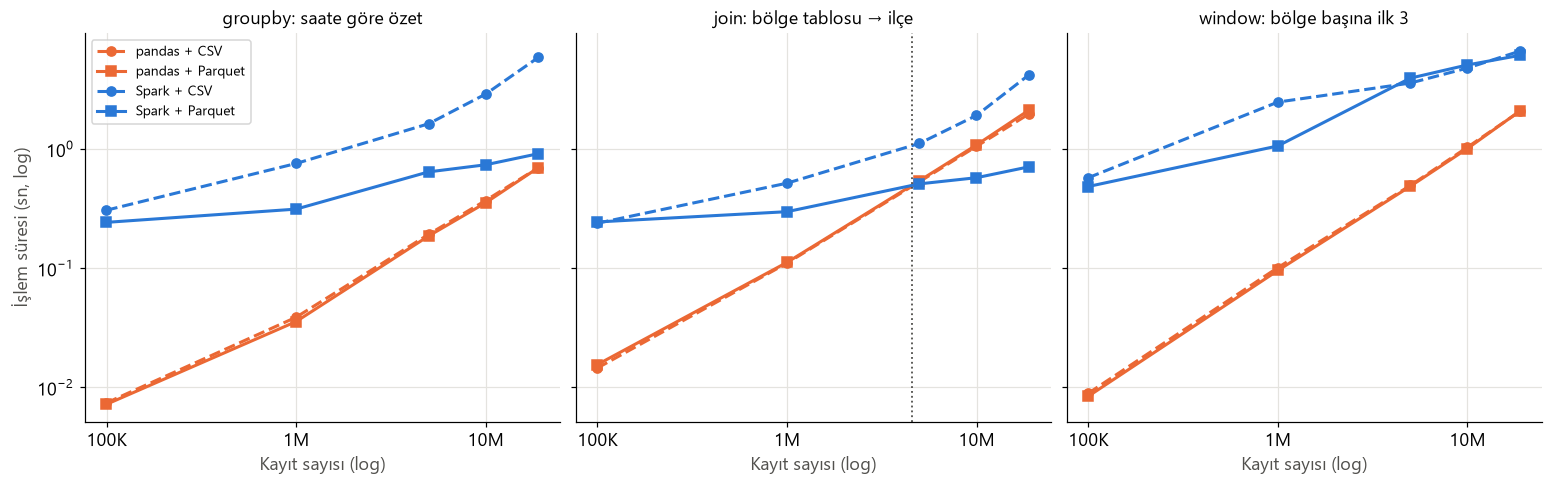

,Spark'ın öne geçtiği boyut (Parquet),19M'de pandas / Spark süresi
groupby: saate göre özet,18.999.282 kayda kadar yok,"0,76×"
join: bölge tablosu → ilçe,"~4,5M","3,00×"
window: bölge başına ilk 3,18.999.282 kayda kadar yok,"0,34×"


In [7]:
ops = summary[summary["op"].isin(bp.OPERATIONS)]
cross_ops = {op: crossover_rows(ops[ops["op"] == op], "parquet_snappy", "seconds_mean") for op in bp.OPERATIONS}
ratio19 = (f19[f19["op"].isin(bp.OPERATIONS) & (f19["format"] == "parquet_snappy")]
           .pivot(index="op", columns="engine", values="seconds_mean"))
join_x = ratio19.loc["join_borough", "pandas"] / ratio19.loc["join_borough", "spark"]
window_x = ratio19.loc["window_top3", "spark"] / ratio19.loc["window_top3", "pandas"]
md(f"**Parquet'te join'de Spark ~{tr_dec(cross_ops['join_borough'] / 1e6, 1)}M kayıttan itibaren önde, "
   f"19M'de {tr_dec(join_x, 1)}× hızlı. window'da ise 19M'de hâlâ {tr_dec(window_x, 1)}× geride.**")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), layout="constrained", sharey=True)
for ax, op in zip(axes, bp.OPERATIONS):
    plot_lines(ax, ops[ops["op"] == op], "seconds_mean")
    log_axes(ax, "İşlem süresi (sn, log)" if ax is axes[0] else "")
    ax.set_title(OP_TITLE[op], fontsize=12)
    if cross_ops[op]:
        ax.axvline(cross_ops[op], color=INK, linestyle=":", linewidth=1.2)
axes[0].legend(fontsize=9)
show(fig)

display(pd.DataFrame({
    "Spark'ın öne geçtiği boyut (Parquet)": {
        OP_TITLE[op]: (f"~{tr_dec(v / 1e6, 1)}M" if v else f"{tr_int(FULL)} kayda kadar yok")
        for op, v in cross_ops.items()},
    "19M'de pandas / Spark süresi": {
        OP_TITLE[op]: tr_dec(ratio19.loc[op, "pandas"] / ratio19.loc[op, "spark"], 2) + "×"
        for op in bp.OPERATIONS},
}))

**Neden join'de Spark kazanıyor?** Spark 265 satırlık bölge tablosunu bütün görevlere yayınlar (**broadcast hash join**). Birleştirmeyi ve kısmi toplamayı tek aşamada, 20 iş parçacığında yapar; 19M satırlık birleşik tabloyu hiç oluşturmaz. pandas `merge` ise önce birleşik tabloyu bellekte yeni bir kopya olarak kurar, sonra ayrı bir `groupby` çalıştırır.

**Neden window'da pandas kazanıyor?** `partitionBy(PULocationID)` bütün satırların bölgeye göre yeniden dağıtılmasını gerektirir (**shuffle**). Satırlar diske yazılıp yeniden okunur, ardından her bölümde sıralama yapılır. Dağılım da dengesizdir: en yoğun bölge (237) verinin yaklaşık %5'ini tek bir göreve yükler. pandas aynı işi tek bir vektörel sıralama ve `groupby.head(3)` ile, veri taşımadan yapar. Tek makinede shuffle'ın getirisi yok, yalnızca maliyeti var. Farkın bir kısmı ise dosya düzeninden geliyor (§8): 19M Parquet 3 row group'tan oluştuğu için Spark onu yalnızca 3 görevle okuyor.

**groupby'da** 19M'de iki motor neredeyse başa baş. Spark'ın paralelliği, sabit maliyetini ancak karşılıyor.

## 6. Bellek

**19M'de tepe bellek: pandas 2,7–3,1 GB, Spark 4,2–4,9 GB.** pandas'ın belleği 6 kolonla kayıt başına ~0,14–0,16 KB artıyor. Bu eğimle 32 GB RAM ~203–241M kayıtta dolar.

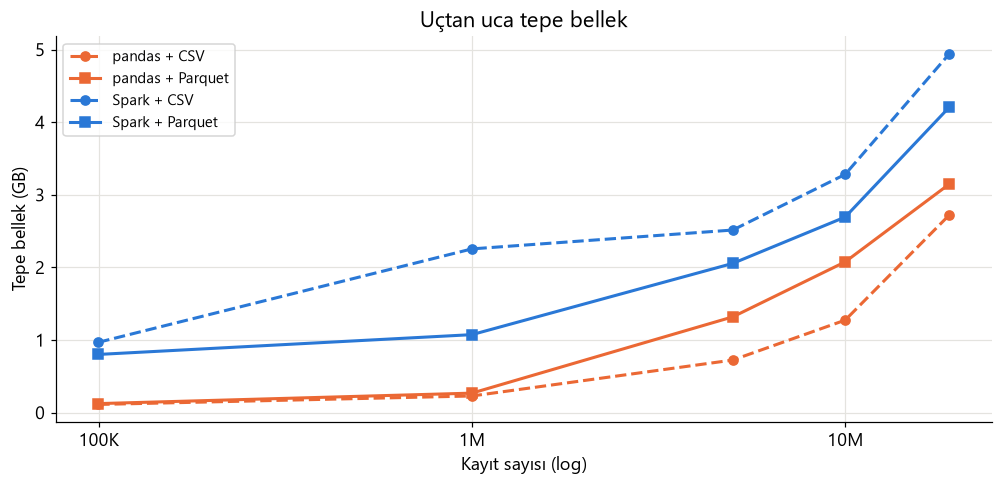

In [8]:
peak = e2e[e2e["size"] == "full"].set_index(["engine", "format"])["peak_rss_mb"] / 1000
per_row = memory_per_row_kb(summary)
RAM_GB = 32
limit = {fmt: RAM_GB * 1024 * 1024 / kb / 1e6 for fmt, kb in per_row.items()}
md(f"**19M'de tepe bellek: pandas {tr_dec(peak[('pandas', 'csv')], 1)}–{tr_dec(peak[('pandas', 'parquet_snappy')], 1)} GB, "
   f"Spark {tr_dec(peak[('spark', 'parquet_snappy')], 1)}–{tr_dec(peak[('spark', 'csv')], 1)} GB.** "
   f"pandas'ın belleği 6 kolonla kayıt başına ~{tr_dec(min(per_row.values()), 2)}–{tr_dec(max(per_row.values()), 2)} KB artıyor. "
   f"Bu eğimle {RAM_GB} GB RAM ~{tr_dec(min(limit.values()), 0)}–{tr_dec(max(limit.values()), 0)}M kayıtta dolar.")

fig, ax = plt.subplots(figsize=(9, 4.3), layout="constrained")
plot_lines(ax, e2e.assign(peak_gb=e2e["peak_rss_mb"] / 1000), "peak_gb")
ax.set_xscale("log")
ax.set_xticks([1e5, 1e6, 1e7], ["100K", "1M", "10M"])
ax.minorticks_off()
ax.set(xlabel="Kayıt sayısı (log)", ylabel="Tepe bellek (GB)", title="Uçtan uca tepe bellek")
ax.legend(fontsize=10)
show(fig)

- **Spark'ın taban maliyeti var.** JVM boşken bile ~0,5 GB tutar. Shuffle tamponlarıyla 19M'de 4–5 GB'a çıkar. En fazla belleği window adımı kullanır.
- **pandas belleği kayıtla doğrusal artar** ve okunan kolon sayısına bağlıdır. Öğrenci 1'in 20 kolonlu ölçümünde eğim ~0,5 KB/kayıttı. Yani tüm kolonlar okunursa sınır birkaç kat erkene çekilir.
- **Sert sınır:** RAM dolduğunda pandas çalışamaz. Spark diske taşarak (spill) veya kümeye dağıtarak devam eder. Doğrusal eğimi sentetik 57M ölçümüyle doğruladık (§8): pandas 9,1 GB; önbellekli Spark'ın belleği sabit heap nedeniyle 6,8 GB'ta duruyor.

## 7. İki motor aynı sonucu verdi mi?

Hız karşılaştırması ancak iki motor **aynı işi** yaptıysa anlamlıdır. Her işlemin sonucu satır sayısı ve checksum ile kaydedildi:

In [9]:
problems = bp.check_consistency(summary)
assert not problems, problems
check = (ops.groupby(["size_label", "op"])
         .agg(kombinasyon=("checksum", "size"), sonuc_satiri=("result_rows", "first"))
         .reset_index())
check["op"] = check["op"].map(OP_TITLE)
check["Doğrulama"] = "Eşleşti"
check = check.pivot(index="op", columns="size_label", values="sonuc_satiri")[SIZES].map(tr_int)
display(check.rename_axis("Sonuç satırı").rename_axis(None, axis=1))
md(f"5 boyut × 3 işlemin **15'inde de** 2 motor × 2 formatın sonuçları birebir aynı (`check_consistency` → {len(problems)} sorun). "
   "window sonucu bölge başına en fazla 3 satırdır; veri büyüdükçe yolculuk görülen bölge sayısı arttığı için satır sayısı da artıyor. "
   "3'ten az yolculuğu olan bölgeler 3'ten az satır verir.")

,100K,1M,5M,10M,19M
Sonuç satırı,,,,,
groupby: saate göre özet,24,24,24,24,24
join: bölge tablosu → ilçe,8,8,8,8,8
window: bölge başına ilk 3,701,762,779,784,786


5 boyut × 3 işlemin **15'inde de** 2 motor × 2 formatın sonuçları birebir aynı (`check_consistency` → 0 sorun). window sonucu bölge başına en fazla 3 satırdır; veri büyüdükçe yolculuk görülen bölge sayısı arttığı için satır sayısı da artıyor. 3'ten az yolculuğu olan bölgeler 3'ten az satır verir.

## 8. Ek deneyler: önbellek, 57M, dosya düzeni

Ana karşılaştırmada Spark her işlemde dosyayı yeniden okuyordu. pandas ise veriyi bir kez belleğe alıyordu. Üç ek deneyle bu karşılaştırmanın sınırlarını sınadım:

1. **Spark + cache:** veri bir kez okunup 20 bölüme dağıtılır ve Spark belleğine alınır; işlemler önbellekten çalışır.
2. **Sentetik 57M:** 19M verinin 3 kopyası art arda yazıldı. Proje kuralı: "veri yeterince büyük değilse sentetik olarak ölçeklendir".
3. **Dosya düzeni:** aynı 19M satır, Parquet'te 3 yerine 23 row group ile.

### 8.1 Önbellek (cache)

In [10]:
cache = summary_all[(summary_all["engine"] == "spark_cache") & summary_all["size"].isin(SIZE_LABEL)].copy()
f19_all = summary_all[summary_all["size"] == "full"]
tbl = f19_all.pivot_table(index="op", columns=["engine", "format"], values="seconds_mean")
tbl = tbl.loc[["load", "startup", *bp.OPERATIONS]]
tbl.columns = [combo_name(e, f) for e, f in tbl.columns]
tbl.index = [{"load": "Yükleme / önbelleğe alma", "startup": "Spark açılışı"}.get(i, OP_TITLE.get(i, i)) for i in tbl.index]
display(tbl.map(lambda v: "—" if pd.isna(v) else tr_dec(v, 2)).rename_axis("19M, sn"))
c = f19_all[f19_all["engine"] == "spark_cache"].set_index(["format", "op"])["seconds_mean"]
p = f19_all[f19_all["engine"] == "pandas"].set_index(["format", "op"])["seconds_mean"]
md(f"**Önbellekteki tabloda Spark join'i {tr_dec(c[('csv', 'join_borough')], 2)} sn'de yapıyor "
   f"(pandas {tr_dec(p[('csv', 'join_borough')], 2)} sn). Ama Parquet'ten önbelleğe almak "
   f"{tr_dec(c[('parquet_snappy', 'load')], 1)} sn sürüyor; pandas aynı dosyayı "
   f"{tr_dec(p[('parquet_snappy', 'load')], 2)} sn'de yüklüyor.**")

,pandas + CSV,pandas + Parquet,Spark + CSV,Spark + Parquet,Spark + cache + CSV,Spark + cache + Parquet
"19M, sn",,,,,,
Yükleme / önbelleğe alma,"18,82","0,37",—,—,"10,50","8,93"
Spark açılışı,—,—,"5,48","5,81","6,85","5,70"
groupby: saate göre özet,"0,70","0,70","5,86","0,91","0,56","0,69"
join: bölge tablosu → ilçe,"1,97","2,12","4,20","0,71","0,47","0,61"
window: bölge başına ilk 3,"2,07","2,09","6,62","6,09","3,34","3,33"


**Önbellekteki tabloda Spark join'i 0,47 sn'de yapıyor (pandas 1,97 sn). Ama Parquet'ten önbelleğe almak 8,9 sn sürüyor; pandas aynı dosyayı 0,37 sn'de yüklüyor.**

**Neden?** Önbellekte veri zaten 20 bölümde ve sütunlu bellek formatında; her işlem dosyayı okumadan 20 iş parçacığında çalışıyor. Ama önbelleğe almak bir kez ödenen bir maliyet: dosyayı okumak, 20 bölüme dağıtmak (shuffle) ve belleğe yazmak. Parquet'te bu maliyet (~9 sn) üç işlemin kazancından (~3 sn) büyük; ancak aynı veri üzerinde iş yükü ~3 kez tekrarlanırsa kâra geçiyor. CSV'de ise önbelleksiz Spark her işlemde metni yeniden parse ettiği için önbellek ilk turda kâra geçiyor.

### 8.2 Sentetik 57M: bellek duvarına doğru

Boyut,19M,57M (sentetik)
Uçtan uca (sn),,
Spark + CSV,"22,2",—
Spark + Parquet,"13,5",—
Spark + cache + CSV,"21,7","42,7"
Spark + cache + Parquet,"19,3","36,8"
pandas + CSV,"23,6","70,7"
pandas + Parquet,"5,3","21,4"


Boyut,19M,57M (sentetik)
Tepe bellek,,
Spark + CSV,"4,9 GB",—
Spark + Parquet,"4,2 GB",—
Spark + cache + CSV,"6,4 GB","6,9 GB"
Spark + cache + Parquet,"5,7 GB","6,8 GB"
pandas + CSV,"2,7 GB","7,9 GB"
pandas + Parquet,"3,1 GB","9,1 GB"


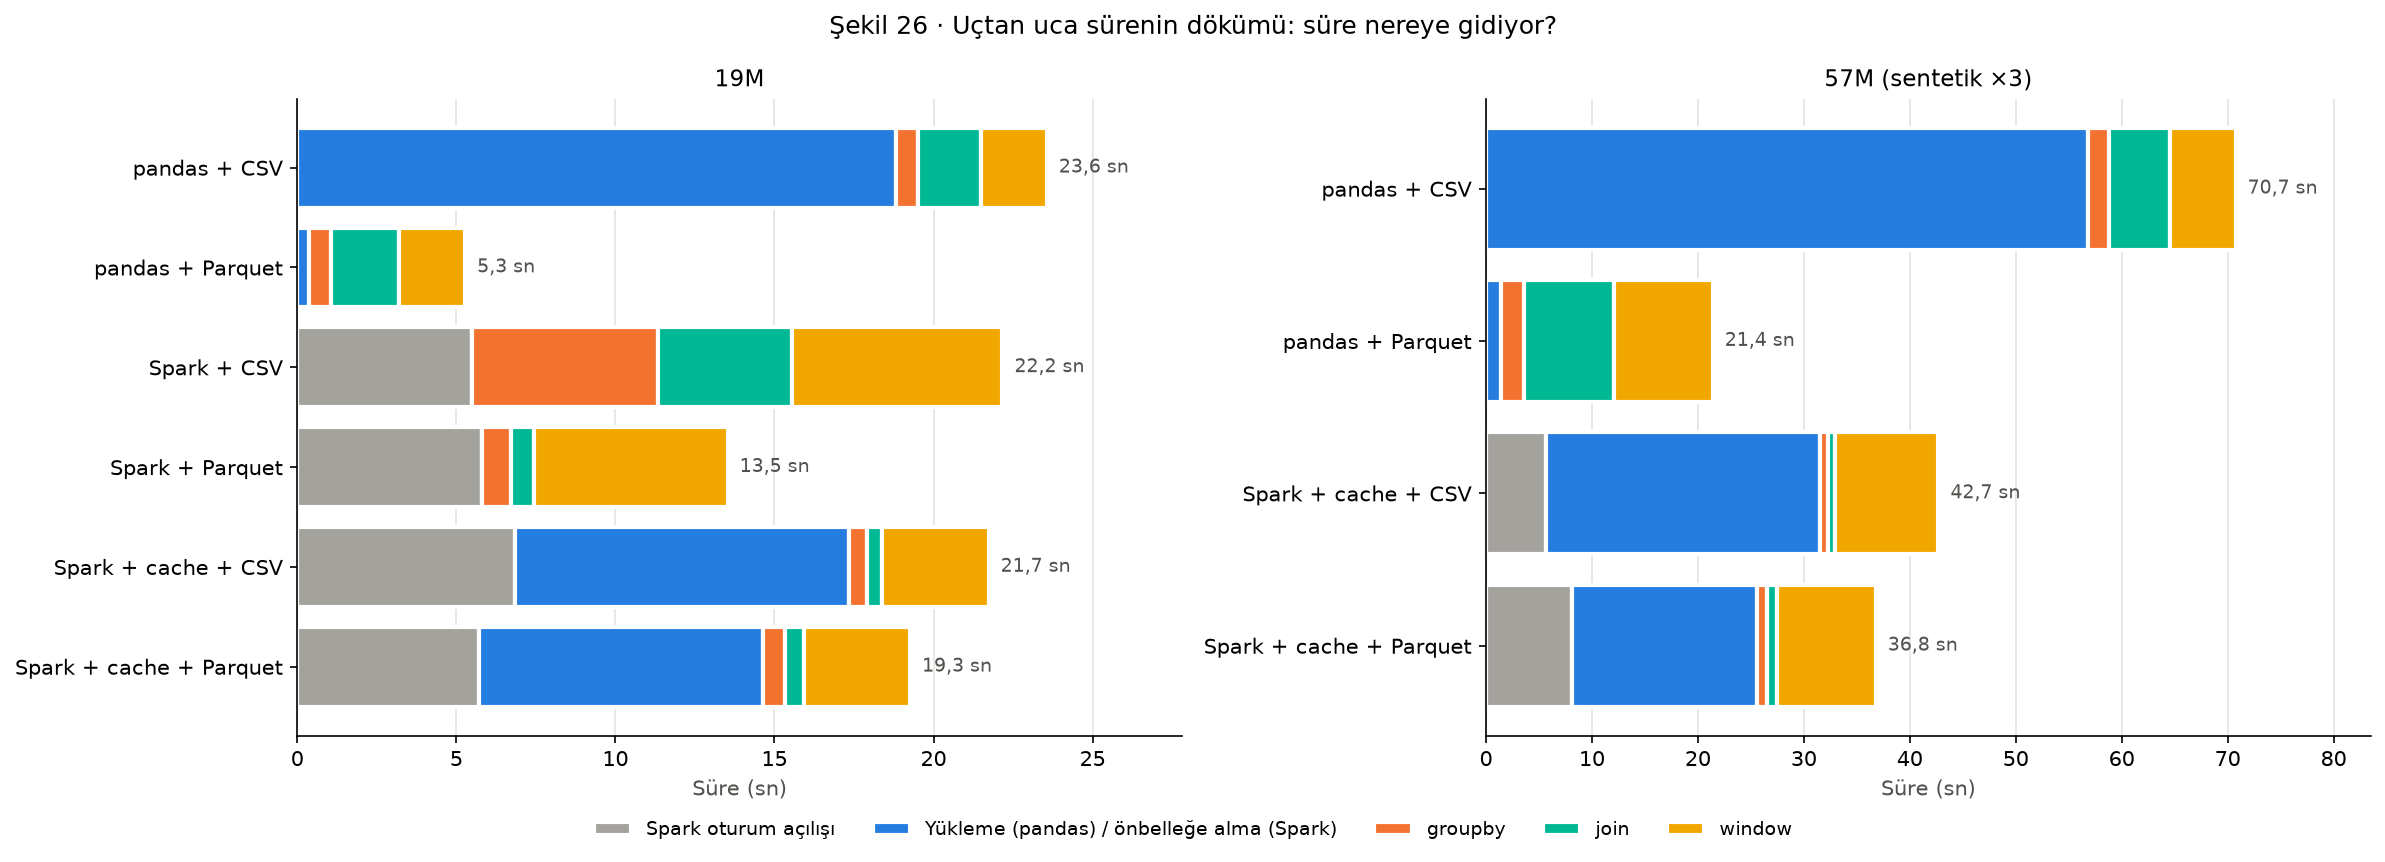

In [11]:
x3 = bp.end_to_end(summary_all[summary_all["size"].isin(["full", "x3"])])
x3["Boyut"] = x3["size"].map({"full": "19M", "x3": "57M (sentetik)"})
x3["Seri"] = [combo_name(e, f) for e, f in zip(x3["engine"], x3["format"])]
display(x3.pivot(index="Seri", columns="Boyut", values="total_s").map(lambda v: "—" if pd.isna(v) else tr_dec(v, 1))
        .rename_axis("Uçtan uca (sn)"))
display(x3.pivot(index="Seri", columns="Boyut", values="peak_rss_mb").map(lambda v: "—" if pd.isna(v) else tr_dec(v / 1000, 1) + " GB")
        .rename_axis("Tepe bellek"))
display(Image(filename=str(root / "reports" / "figures" / "26_s5_time_breakdown.png"), width=1000))

**Neden?** pandas + Parquet 57M'de bile uçtan uca en hızlı (21,4 sn), ama süresi veriden hızlı artıyor (3× veri → 4× süre); önbellekli Spark 1,9×. join'de Spark 9× önde. Bellekte tablo dönüyor: pandas 9,1 GB ile ilk kez Spark'ı (6,8 GB) geçiyor. Spark'ın belleği 6 GB'lık sabit heap'le sınırlı kalıyor (sığmayan önbellek bölümleri diske taşabilir); pandas'ın belleği kayıtla doğrusal büyümeye devam ediyor.

### 8.3 Dosya düzeni: Spark kaç çekirdek kullanıyor?

In [12]:
lay = summary_all[summary_all["size"].isin(["full", "full_rg16"]) & (summary_all["format"] == "parquet_snappy")
                  & summary_all["engine"].isin(["pandas", "spark"]) & summary_all["op"].isin(["load", *bp.OPERATIONS])]
lay = lay.pivot_table(index=["engine", "op"], columns="size", values="seconds_mean")
lay["hızlanma"] = lay["full"] / lay["full_rg16"]
display(lay.rename(columns={"full": "3 row group (sn)", "full_rg16": "23 row group (sn)"})
        .map(lambda v: tr_dec(v, 2)))
w = lay.loc[("spark", "window_top3")]
md(f"**Aynı satırlar, yalnızca row group boyutu farklı: Spark window {tr_dec(w['full'], 2)} → {tr_dec(w['full_rg16'], 2)} sn. "
   "pandas etkilenmiyor.**")

size                3 row group (sn) 23 row group (sn) hızlanma
engine op                                                      
pandas groupby_hour             0,70              0,69     1,02
       join_borough             2,12              2,04     1,04
       load                     0,37              0,25     1,47
       window_top3              2,09              2,08     1,01
spark  groupby_hour             0,91              0,84     1,08
       join_borough             0,71              0,64     1,11
       window_top3              6,09              3,85     1,58

**Aynı satırlar, yalnızca row group boyutu farklı: Spark window 6,09 → 3,85 sn. pandas etkilenmiyor.**

**Neden?** Parquet'te okunabilecek en küçük birim **row group**'tur. Öğrenci 1'in dosyaları tek dosya ve 128 MB'lık row group'larla yazıldı: 19M dosyası 3 row group. Spark bir row group'u bölemediği için dosyayı 3 görevle okuyor (20 iş parçacığının 3'ü). groupby ve join dosyadan okurken zaten hızlı (sütunlu okuma), ama window'da okumanın ardından gelen shuffle 3 görevden besleniyor. pandas'ın okuyucusu (pyarrow) kolonları paralel çözdüğü için row group sayısından etkilenmiyor.

## 9. Dashboard

`reports/dashboard/index.html`, beş öğrencinin sonuçlarını tek sayfada toplar: veri büyüklüğü ve formatlar (S1), temizlik (S2), aggregation bulguları (S3), ML karşılaştırması (S4) ve işleme performansı (S5). Sayfa tek dosyadır, tarayıcıda çift tıklayınca açılır. Sunucu veya ek kütüphane gerekmez. S5 grafiğinde işlem ve metrik seçilebilir.

Sayfayı yeniden üretmek için: `python -m src.dashboard`

In [13]:
dashboard = root / "reports" / "dashboard" / "index.html"
assert dashboard.exists()
md(f"Dosya: `reports/dashboard/index.html` ({tr_dec(dashboard.stat().st_size / 1024, 0)} KB). "
   "Jupyter'de aşağıda gömülü görünür; görünmüyorsa dosyayı tarayıcıda açın.")
IFrame("../reports/dashboard/index.html", width="100%", height=640)

Dosya: `reports/dashboard/index.html` (47 KB). Jupyter'de aşağıda gömülü görünür; görünmüyorsa dosyayı tarayıcıda açın.

## 10. Sonuç

**Araştırma sorusu:** Veri büyüdükçe klasik yaklaşım ne zaman yetersiz kalıyor?

1. **pandas + CSV, ~16M kayıtta Spark'ın gerisine düşüyor.** Darboğaz işlemin kendisi değil, tek çekirdekte CSV parse etmek.
2. **Formatı değiştirmek motoru değiştirmekten daha etkili.** pandas + Parquet sentetik 57M'de bile en hızlı seçenek (21,4 sn; önbellekli Spark 36,8 sn). Ama süresi veriden hızlı artıyor; Spark'ın sabit maliyetleri ancak çok büyük veride amorti oluyor.
3. **Cevap işleme göre değişiyor.** join'de Spark ~4,5M'den itibaren önde (57M'de 9×), window'da 57M'e kadar geride ya da başa baş. "Büyük veri → Spark" genellemesi işlem türünü hesaba katmalı.
4. **Spark'ın verimi dosya düzenine ve çalışma modeline bağlı.** Tek dosya Parquet Spark'ı 3 çekirdekte bırakıyor; önbellek işlemleri hızlandırıyor ama yükleme maliyeti ancak tekrarlanan sorgularda amorti oluyor.
5. **Klasik yaklaşımın sert sınırı bellek.** 57M'de pandas 9,1 GB ile Spark'ı geçti ve doğrusal büyüyor; 32 GB ~200M kayıtta (6 kolon) dolar. RAM dolduğunda pandas çalışamaz.

### Sorulursa

| Soru | Kısa cevap ve kanıt |
|---|---|
| Okuma süresini Öğrenci 1 ölçmedi mi? | S1 okumayı ve depolamayı ölçtü. Burada okunan veri üzerindeki **işlem** ölçüldü (§2). |
| Spark neden küçük veride bu kadar yavaş? | Oturum açılışı ~5,5 sn, her işlemde planlama ve görev başlatma maliyeti var (§3). |
| `cache()` kullansaydın? | Ölçtük (§8.1): işlemler hızlanıyor (19M join 0,47 sn) ama önbelleğe alma ~9 sn; Parquet'te ancak ~3 tekrarda kâra geçiyor. |
| Veri yeterince büyük mü? | 19M gerçek veri; ayrıca 57M sentetik ölçtük (§8.2). Kopyalar blok blok yazıldı, dosya oranı 2,999×. |
| İki motor gerçekten aynı işi mi yaptı? | 15 işlem × boyut kombinasyonunun hepsinde checksum'lar eşleşti (§7). |
| window neden Spark'ta yavaş? | İki neden: dosya 3 row group → 3 görevle okunuyor (23 row group'la 6,1 → 3,85 sn, §8.3) ve shuffle: satırlar bölgeye göre yeniden dağıtılıp diske yazılıyor (§5). |
| Kümede sonuç değişir mi? | Muhtemelen. Biz tek makinede `local[*]` ile ölçtük; yatay ölçeklenme test edilmedi. |

Ayrıntılar: [Teknik rapor](../docs/technical_report_s5.md) · [Tam notebook](05_processing_benchmark.ipynb) · [Sınav soruları](../docs/exam_questions_s5.md)